In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')  # Ignora las advertencias durante la ejecución
# Lee el csv y lo guarda en una variable llamada "data"
data = pd.read_csv("recursos_humanos (1).csv")
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [2]:
data = pd.get_dummies(data, columns=["sales", "salary"], dtype=int)
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [6]:
# Pre-Procesamiento de datos y selección
data.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales_IT                   int64
sales_RandD                int64
sales_accounting           int64
sales_hr                   int64
sales_management           int64
sales_marketing            int64
sales_product_mng          int64
sales_sales                int64
sales_support              int64
sales_technical            int64
salary_high                int64
salary_low                 int64
salary_medium              int64
dtype: object

In [7]:
feature_df = data.drop(["left"], axis=1)
X = np.asarray(feature_df)
X[0:5]

array([[3.80e-01, 5.30e-01, 2.00e+00, 1.57e+02, 3.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [8.00e-01, 8.60e-01, 5.00e+00, 2.62e+02, 6.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [1.10e-01, 8.80e-01, 7.00e+00, 2.72e+02, 4.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [7.20e-01, 8.70e-01, 5.00e+00, 2.23e+02, 5.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [3.70e-01, 5.20e-01, 2.00e+00, 1.59e+02, 3.00e+00, 0.00e+00,


In [8]:
data["left"] = data["left"].astype("int")
y = np.asarray(data["left"])
y[0:5]

array([1, 1, 1, 1, 1])

In [9]:
# Creación de grupos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                test_size=0.2, random_state=4)
print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (11999, 20) (11999,)
Grupo de prueba (3000, 20) (3000,)


In [10]:
# Estandarizamos para SVM
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# Modelos e indicadores para la comparación
from sklearn import svm
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
modelos = {}
resultados = []

In [12]:
# Modelo con SVM: Kernel RBF
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)
modelos["RBF"] = clf

In [13]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 1, 0, 0, 0])

In [14]:
# Creación de matriz de confusión
cm = confusion_matrix(y_test, yhat, labels=[0, 1])
cm

array([[2227,   60],
       [  77,  636]])

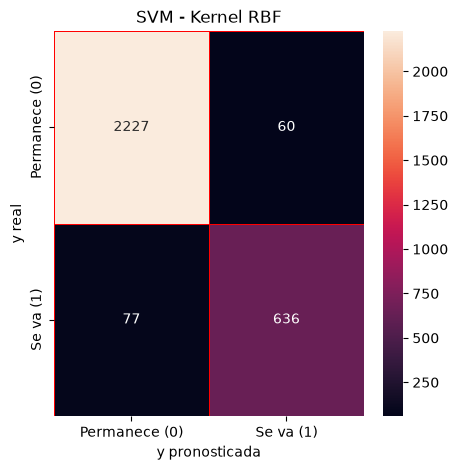

In [16]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax,
            xticklabels=["Permanece (0)", "Se va (1)"],
            yticklabels=["Permanece (0)", "Se va (1)"])
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("SVM - Kernel RBF")
plt.show()

In [17]:
# Estadísticas de desempeño
print(classification_report(y_test, yhat, labels=[0, 1], zero_division=0))
resultados.append({
    "Kernel": "RBF",
    "Accuracy": accuracy_score(y_test, yhat),
    "F1 macro": f1_score(y_test, yhat, average="macro", zero_division=0),
    "F1 clase 1": f1_score(y_test, yhat, pos_label=1, zero_division=0)
})

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      2287
           1       0.91      0.89      0.90       713

    accuracy                           0.95      3000
   macro avg       0.94      0.93      0.94      3000
weighted avg       0.95      0.95      0.95      3000



In [18]:
# Modelación con SVM: Kernel Lineal
clf = svm.SVC(kernel="linear")
clf.fit(X_train, y_train)
modelos["Lineal"] = clf

In [19]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 1, 0, 0, 0])

In [20]:
# Creación de matriz de confusión
cm = confusion_matrix(y_test, yhat, labels=[0, 1])
cm

array([[2152,  135],
       [ 524,  189]])

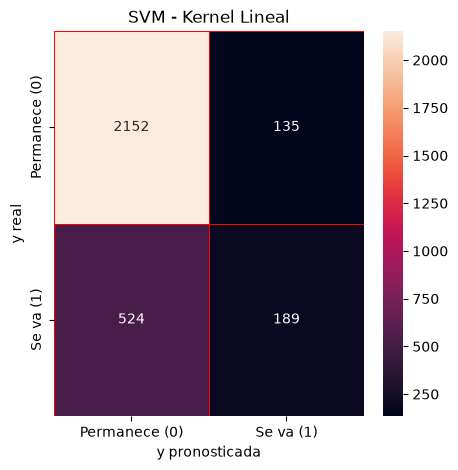

In [21]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax,
            xticklabels=["Permanece (0)", "Se va (1)"],
            yticklabels=["Permanece (0)", "Se va (1)"])
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("SVM - Kernel Lineal")
plt.show()

In [22]:
# Estadísticas de desempeño
print(classification_report(y_test, yhat, labels=[0, 1], zero_division=0))
resultados.append({
    "Kernel": "Lineal",
    "Accuracy": accuracy_score(y_test, yhat),
    "F1 macro": f1_score(y_test, yhat, average="macro", zero_division=0),
    "F1 clase 1": f1_score(y_test, yhat, pos_label=1, zero_division=0)
})

              precision    recall  f1-score   support

           0       0.80      0.94      0.87      2287
           1       0.58      0.27      0.36       713

    accuracy                           0.78      3000
   macro avg       0.69      0.60      0.62      3000
weighted avg       0.75      0.78      0.75      3000



In [23]:
# Modelación con SVM: Kernel Polinomial
clf = svm.SVC(kernel="poly")
clf.fit(X_train, y_train)
modelos["Polinomial"] = clf

In [24]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 1, 0, 0, 0])

In [25]:
# Creación de matriz de confusión
cm = confusion_matrix(y_test, yhat, labels=[0, 1])
cm

array([[2234,   53],
       [ 127,  586]])

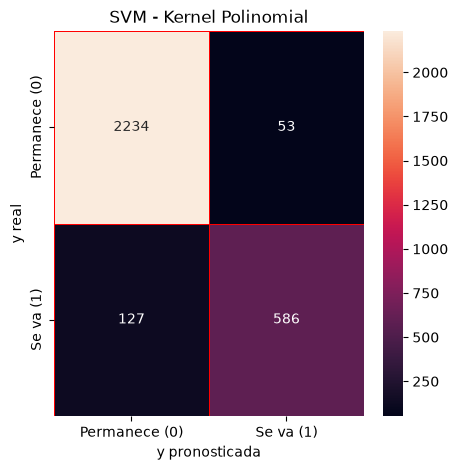

In [26]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax,
            xticklabels=["Permanece (0)", "Se va (1)"],
            yticklabels=["Permanece (0)", "Se va (1)"])
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("SVM - Kernel Polinomial")
plt.show()

In [27]:
# Estadísticas de desempeño
print(classification_report(y_test, yhat, labels=[0, 1], zero_division=0))
resultados.append({
    "Kernel": "Polinomial",
    "Accuracy": accuracy_score(y_test, yhat),
    "F1 macro": f1_score(y_test, yhat, average="macro", zero_division=0),
    "F1 clase 1": f1_score(y_test, yhat, pos_label=1, zero_division=0)
})

              precision    recall  f1-score   support

           0       0.95      0.98      0.96      2287
           1       0.92      0.82      0.87       713

    accuracy                           0.94      3000
   macro avg       0.93      0.90      0.91      3000
weighted avg       0.94      0.94      0.94      3000



In [28]:
# Modelación con SVM: Kernel Sigmoid
clf = svm.SVC(kernel="sigmoid")
clf.fit(X_train, y_train)
modelos["Sigmoid"] = clf

In [29]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 1, 1, 0, 0])

In [30]:
# Creación de matriz de confusión
cm = confusion_matrix(y_test, yhat, labels=[0, 1])
cm

array([[1790,  497],
       [ 543,  170]])

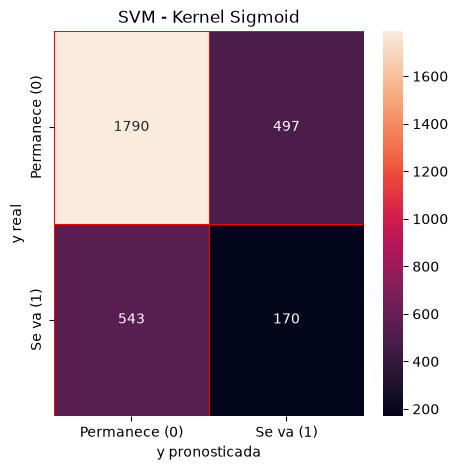

In [31]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax,
            xticklabels=["Permanece (0)", "Se va (1)"],
            yticklabels=["Permanece (0)", "Se va (1)"])
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("SVM - Kernel Sigmoid")
plt.show()

In [32]:
# Estadísticas de desempeño
print(classification_report(y_test, yhat, labels=[0, 1], zero_division=0))
resultados.append({
    "Kernel": "Sigmoid",
    "Accuracy": accuracy_score(y_test, yhat),
    "F1 macro": f1_score(y_test, yhat, average="macro", zero_division=0),
    "F1 clase 1": f1_score(y_test, yhat, pos_label=1, zero_division=0)
})

              precision    recall  f1-score   support

           0       0.77      0.78      0.77      2287
           1       0.25      0.24      0.25       713

    accuracy                           0.65      3000
   macro avg       0.51      0.51      0.51      3000
weighted avg       0.65      0.65      0.65      3000



In [33]:
# Comparación de indicadores
comparacion = pd.DataFrame(resultados)
comparacion.sort_values(by="F1 macro", ascending=False)

,Kernel,Accuracy,F1 macro,F1 clase 1
0,RBF,0.954333,0.936463,0.902768
2,Polinomial,0.940000,0.914069,0.866864
1,Lineal,0.780333,0.615865,0.364513
3,Sigmoid,0.653333,0.510634,0.246377


In [34]:
# Selección del mejor Kernel por F1 macro
mejor_kernel = comparacion.sort_values(by=["F1 macro", "F1 clase 1"], ascending=False).iloc[0]["Kernel"]
mejor_modelo = modelos[mejor_kernel]
print("Kernel seleccionado:", mejor_kernel)
print("F1 macro:", comparacion.loc[comparacion["Kernel"] == mejor_kernel, "F1 macro"].iloc[0])

Kernel seleccionado: RBF
F1 macro: 0.9364634636316711


In [35]:
# Características del empleado indicado en la actividad
nuevo_empleado = pd.DataFrame({
    "satisfaction_level": [0.5],
    "last_evaluation": [0.75],
    "number_project": [4],
    "average_montly_hours": [200],
    "time_spend_company": [4],
    "Work_accident": [0],
    "promotion_last_5years": [0],
    "sales": ["sales"],
    "salary": ["medium"]
})
nuevo_empleado

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales,salary
0,0.5,0.75,4,200,4,0,0,sales,medium


In [36]:
# Aplicar la misma recodificación y el mismo orden de variables
nuevo_empleado = pd.get_dummies(nuevo_empleado, columns=["sales", "salary"], dtype=int)
nuevo_empleado = nuevo_empleado.reindex(columns=feature_df.columns, fill_value=0)
X_nuevo = scaler.transform(nuevo_empleado)

# Pronóstico con el Kernel seleccionado
pronostico = mejor_modelo.predict(X_nuevo)
print("Kernel utilizado:", mejor_kernel)
print("Pronóstico:", int(pronostico[0]))
print("Interpretación:", "Dejaría la empresa" if pronostico[0] == 1 else "Permanecería en la empresa")

Kernel utilizado: RBF
Pronóstico: 0
Interpretación: Permanecería en la empresa
